# Import Before Use

In [ ]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import random
from scipy import stats
import pandas as pd
import sklearn

*11*/17/2024<br>
#Data Sets

1.   get mean
2.   get median
3.   get mode





In [ ]:
speed = [99,86,87,88,111,86,103,87,94,78,77,85,86]

# get mean
x = np.mean(speed)
print('the mean is', x)
print()

# get median
x = np.median(speed)
print('the median is', x)
print()

# get mode
x = stats.mode(speed)
print('the mode is', x)

the mean is 89.76923076923077

the median is 87.0

the mode is ModeResult(mode=86, count=3)


11/18/2024 <br>

#Standard Deviation

- The amount of variation each element in a data set has from the mean (the average)
- represented by the symbol Sigma: σ
- low standard deviation = numbers are close to the mean.
- high standard deviation = elements have wider range.


Variance
- Another number to represent variation in data set
- represented by the symbol Sigma Squared: σ^2
- The square of Standard Deviation

<br>


In [ ]:
speed = [86,87,88,86,87,85,86]
x = np.std(speed)
print(speed, '\nstandard deviation: ', x)
x = np.var(speed)
print('variance: ', x)

print()

speed = [32,111,138,28,59,77,97]
x = np.std(speed)
print(speed, '\nstandard deviation: ', x)
x = np.var(speed)
print('variance: ', x)

[86, 87, 88, 86, 87, 85, 86] 
standard deviation:  0.9035079029052513
variance:  0.8163265306122449

[32, 111, 138, 28, 59, 77, 97] 
standard deviation:  37.84501153334721
variance:  1432.2448979591834


11/22/2024<br>
Percentile

The value that the given percentage of a data set is lower than. The 90th percentile is 61. This means 90% of the data is lower than  61.

In [ ]:
ages = [5,31,43,48,50,41,7,11,15,39,80,82,32,2,8,6,25,36,27,61,31]

x = np.percentile(ages, 90)

print(x)

61.0


11/22/2024<br>
Data Distribution

Numpy can make large and randomized data sets with the function random.uniform()<br>
The parameters are as follows: minimum value, maximum value, # of elements you want to generate. <br>
You can generate a histogram or scatter plot using MatPlotLib. <br>
The graphs below demonstrate uniform and normal data sets respoectively:
- uniform -
- normal - tends to concentrate around the mean value

[0.93484473 9.36755879 7.43928296 ... 2.28574947 7.32777718 2.15800913]


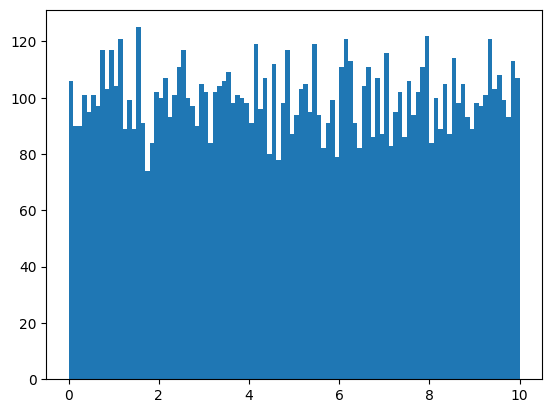

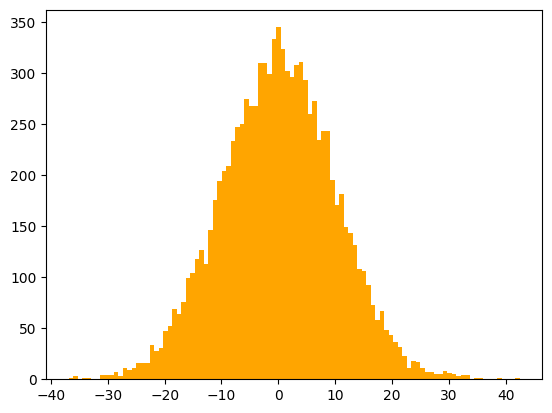

In [ ]:
x = np.random.uniform(0.0, 10.0, 10000)
plt.hist(x,100)
plt.show()

y = np.random.normal(0.0, 10.0, 10000)
plt.hist(y,100,color='orange')
plt.show()

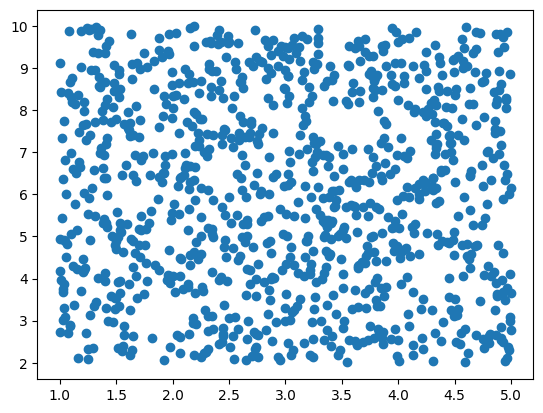

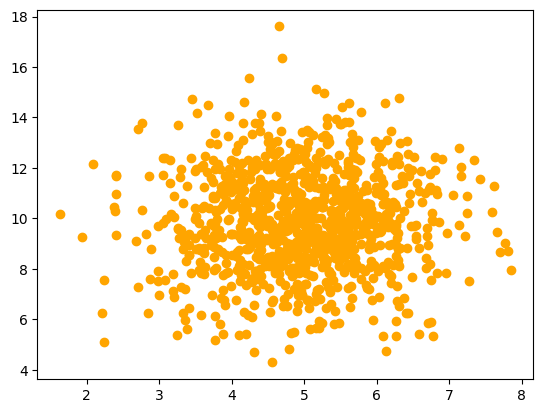

In [ ]:
x = np.random.uniform(5.0, 1.0, 1000)
y = np.random.uniform(10.0, 2.0, 1000)
plt.scatter(x, y)
plt.show()

x = np.random.normal(5.0, 1.0, 1000)
y = np.random.normal(10.0, 2.0, 1000)
plt.scatter(x, y,c='orange')
plt.show()

11/28/2024<br>
#Linear Regression<br>
Relationship between values (used in ML to predict future events)

Two types:
- Linear Regression - straight line through (roughly) all points on a graph
- Polynomial Regression - curved line through (roughly) all points on a graph

The example below illustrates Linear Regression. The variable *r* represents the relationship. Values 1 and -1 indicate aperfect relationship. The value 0 indicates there is no relation.

Enter car age: 10
Predicted speed: 85.59308314937454


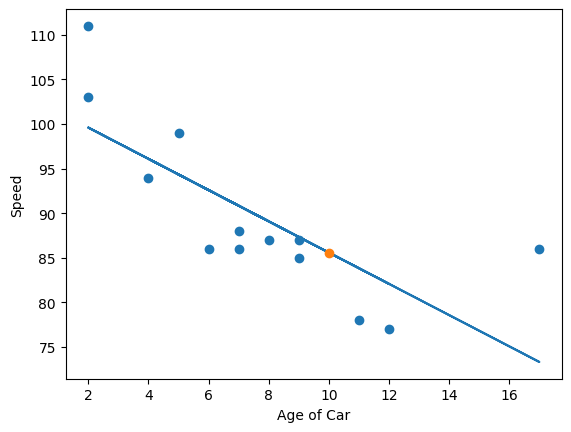

-0.758591524376155


In [ ]:
x = [5,7,8,7,2,17,2,9,4,11,12,9,6]
y = [99,86,87,88,111,86,103,87,94,78,77,85,86]

#defines multiple values from the linregress function's returned values
slope, intercept, r, p, std_err = stats.linregress(x, y)

def myfunc(x):
  return slope * x + intercept
# basically, slope-intercept form in math

#creates a list: map function iterates over each element and applies myfunc()
mymodel = list(map(myfunc, x))

plt.scatter(x, y)
plt.plot(x, mymodel)

predictionAge = int(input("Enter car age: "))
predictionSpd = myfunc(predictionAge)
print('Predicted speed:', predictionSpd)

xpoint = np.array([predictionAge])
ypoint = np.array([predictionSpd])
plt.plot(xpoint,ypoint, 'o')

plt.xlabel("Age of Car")
plt.ylabel("Speed")
plt.show()
print(r)

Polynomial Regression - curved line through (roughly) all points on a graph
<br><br>
The example below illustrates Polynomial Regression. The variable *r-squared* represents the relationship.<br>
A value of 0 means there is no relationship. A value of 1 is a perfect relationship.

Enter x-value: 15
Predicted y-value: 79.90247701009666


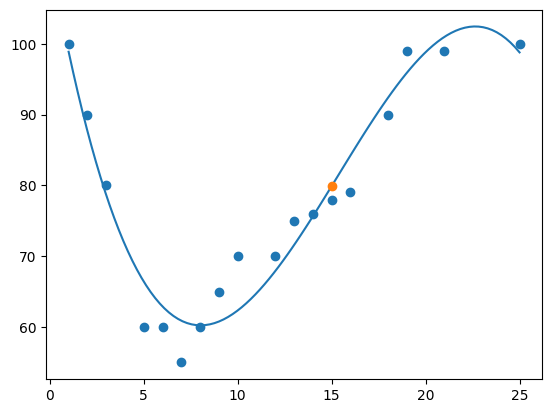

0.9400400029425291
This is a really good relationship!


In [ ]:
from sklearn.metrics import r2_score

x = [1,2,3,5,6,7,8,9,10,12,13,14,15,16,18,19,21,25]
y = [100,90,80,60,60,55,60,65,70,70,75,76,78,79,90,99,99,100]

#numPy has a function to make a line - parameters x, y, and the degree of the polynomial
mymodel = np.poly1d(np.polyfit(x, y, 3))
#start at 1, end at 25, maximum y = 100
myline = np.linspace(1, 25, 100)

plt.scatter(x, y)
plt.plot(myline, mymodel(myline))

predictionX = int(input("Enter x-value: "))
predictionY = mymodel(predictionX)
print('Predicted y-value:', predictionY)

xpoint = np.array([predictionX])
ypoint = np.array([predictionY])
plt.plot(xpoint,ypoint, 'o')

plt.show()
print(r2_score(y, mymodel(x)))
print('This is a really good relationship!')

11/30/2024<br>
#Train/Test
- Train: Blue
- Test: Orange
- Prediction: Yellow diamond

Enter x-value: 3
Predicted y-value: 49.950624612499894


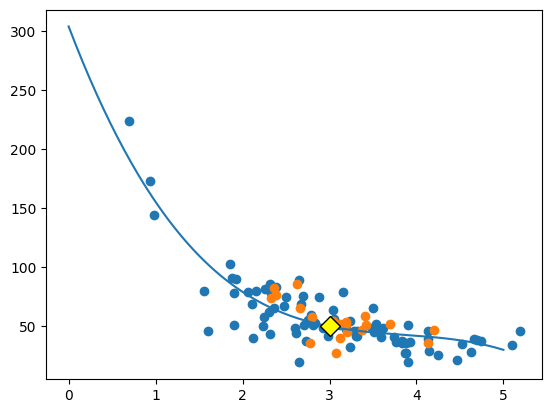

In [ ]:
np.random.seed(1)

x = np.random.normal(3, 1, 100)
y = np.random.normal(150, 40, 100) / x

train_x = x[:80]
train_y = y[:80]

test_x = x[80:]
test_y = y[80:]

mymodel = np.poly1d(np.polyfit(x, y, 3))
myline = np.linspace(0, 5, 250)

predictionX = int(input("Enter x-value: "))
predictionY = mymodel(predictionX)
print('Predicted y-value:', predictionY)

xpoint = np.array([predictionX])
ypoint = np.array([predictionY])

plt.scatter(train_x, train_y)
plt.scatter(test_x, test_y)
plt.plot(myline, mymodel(myline))
plt.plot(xpoint,ypoint, 'D', c='yellow', ms = 10, mec = 'black')
plt.show()

The below table illustrates a confusion matrix for spam calls. <br>
The program that created this confusion matrix correctly predicted whether incoming calls were spam or not 9600 times (green boxes) <br>
There were times that the program was incorrect about whether incoming calls were spam 400 times.<br>
There is a relatively high success rate here. Good job, bot!



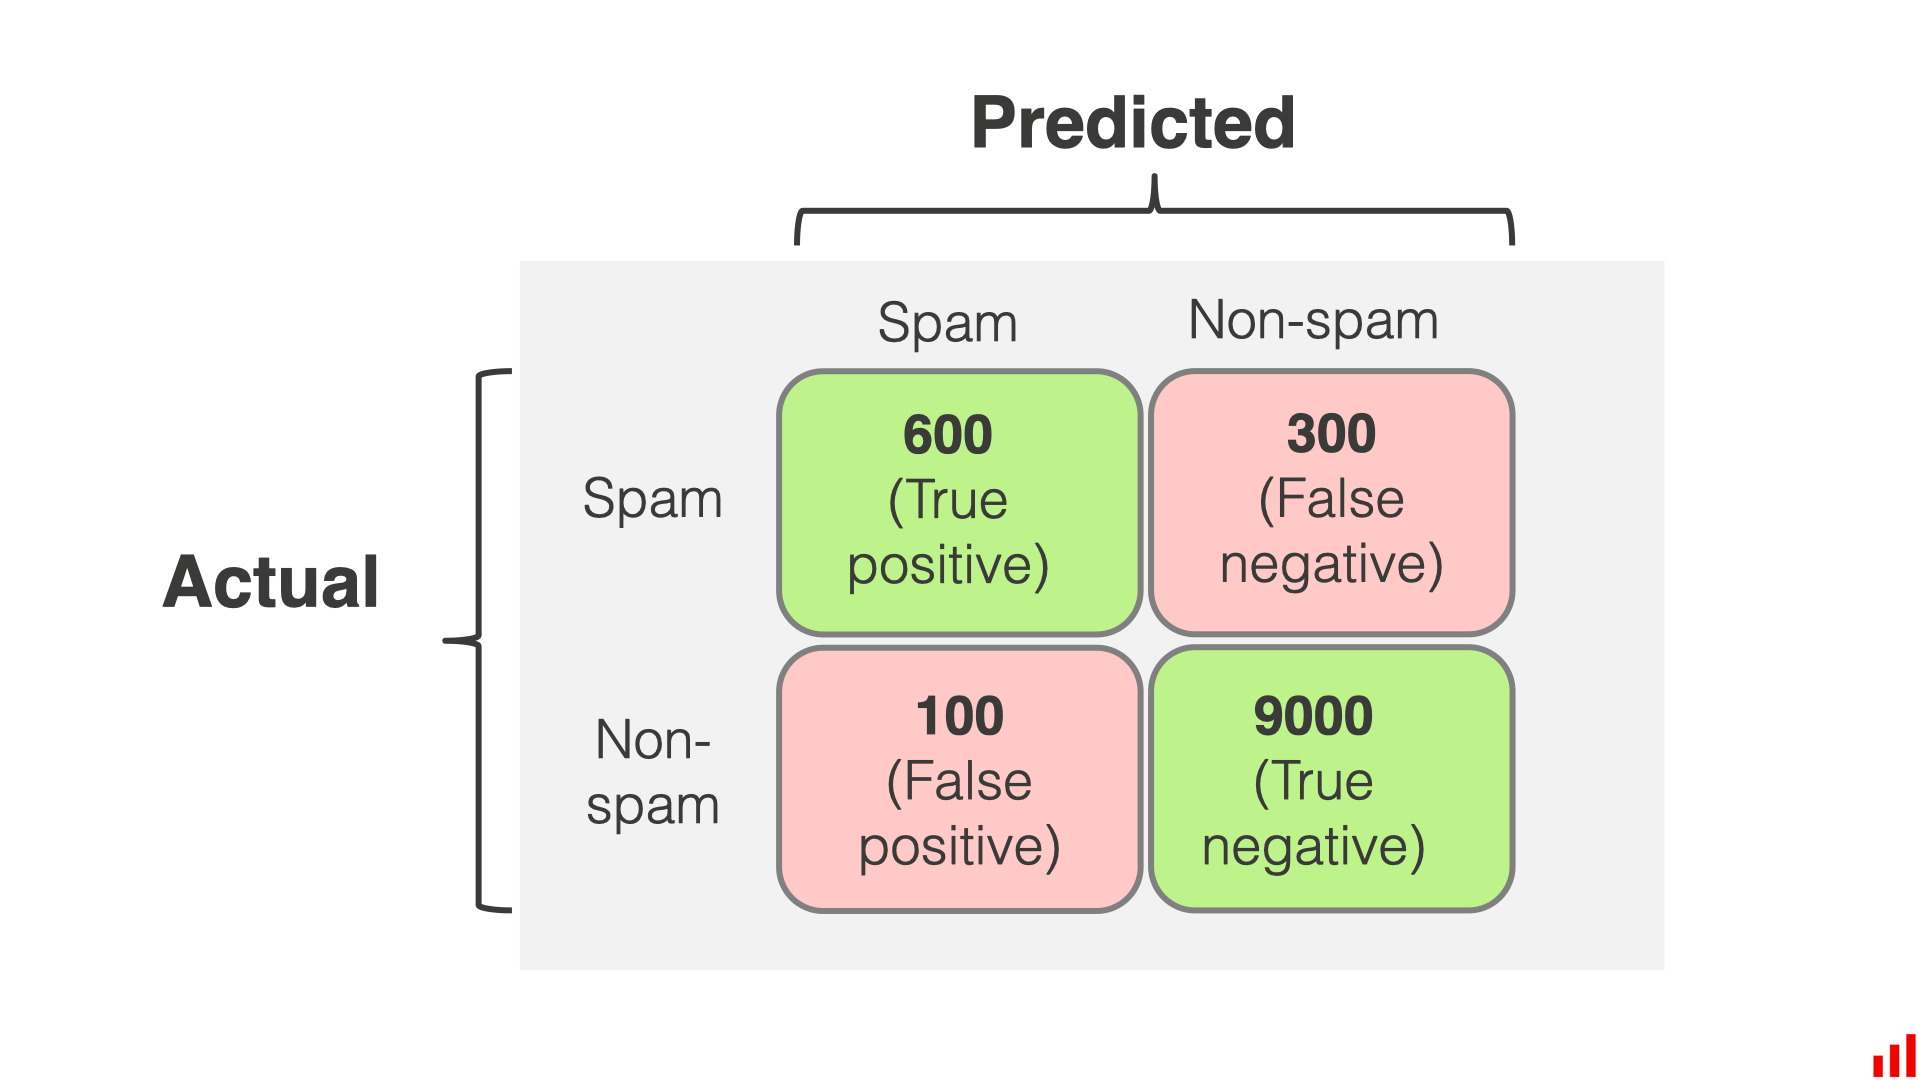

12/12/2024
# Confusion Matrix Vocabulary
<br>

**Accuracy:** How often was the model correct?<br>
*(True Positive + True Negative) / Total Predictions* <br><br>

**Precision:** What percent of predicted positives were true?<br>
 *True Positive / (True Positive + False Positive)*<br><br>

**Recall (Sensitivity):** How many times did the program correctly predict positive values? <br>
*True Positive / (True Positive + False Negative)*<br><br>

**Specificity:** How many times did the program correctly predict negative values?<br>
*True Negative / (True Negative + False Positive)*<br><br>

**F1 Score:** How many times did the program correctly predict negative values?<br>
*2 * ((Precision * Sensitivity) / (Precision + Sensitivity))*<br>
This is the harmonic mean of Precision and Sensitivity. It takes into account false predictions.
<br>
The harmonic mean of positive integers a and b is 2ab/(a+b)
<br>

[[ 11  76]
 [ 88 825]]


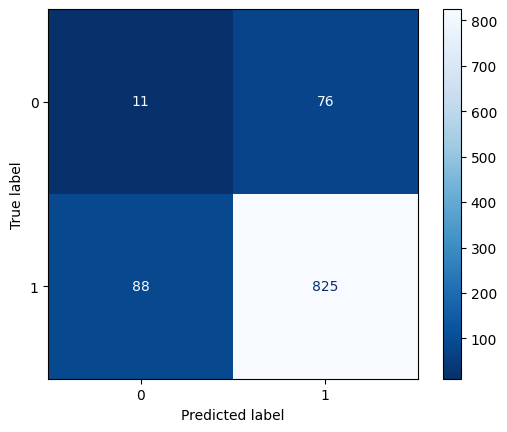

Accuracy: 83.6 %
Precision: 91.56492785793563 %
Recall: 90.36144578313254 %
Specificity: 12.643678160919542 %

F1 Score: 0.9095920617420066


In [ ]:
from sklearn import metrics

actual = np.random.binomial(1, 0.9, size = 1000)
predicted = np.random.binomial(1, 0.9, size = 1000)

confusionMatrix = metrics.confusion_matrix(actual, predicted)
print (confusionMatrix)
# using sklearn, creates confusion matrix

cm_display = metrics.ConfusionMatrixDisplay(confusion_matrix = confusionMatrix, display_labels = [0, 1])
cm_display.plot(cmap = 'Blues_r')
plt.show()
# makes a more visible display using CMD and MPL
'''
True Negative (Top-Left Quadrant)
False Positive (Top-Right Quadrant)
False Negative (Bottom-Left Quadrant)
True Positive (Bottom-Right Quadrant)
'''

Accuracy = metrics.accuracy_score(actual, predicted)
print('Accuracy:', Accuracy*100, '%')

Precision = metrics.precision_score(actual, predicted)
print('Precision:', Precision*100, '%')

Recall = metrics.recall_score(actual, predicted)
print('Recall:', Recall*100, '%')

Specificity = metrics.recall_score(actual, predicted, pos_label=0)
print('Specificity:', Specificity*100, '%')

print()

F1Score = metrics.f1_score(actual, predicted)
print('F1 Score:', F1Score)

12/23/24
#Logistic Regression
- Predicts classifcation rather than number
- Binomial: 2 classifications
- Multinomial: 3+ classifications

This example, derived from w3schools, is binomial. It only has 2 outcomes -- whether the tumor is cancerous or not.

In [ ]:
#x: size of a tumor in centimeters.
x = np.array([3.78, 2.44, 2.09, 0.14, 1.72, 1.65, 4.92, 4.37, 4.96, 4.52, 3.69, 5.88]).reshape(-1,1)
#Note: x has to be reshaped into a column from a row for the LogisticRegression() function to work.


#y: is tumor cancerous (0 for "No", 1 for "Yes").
y = np.array([0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1])

logr = sklearn.linear_model.LogisticRegression()
logr.fit(x,y)

#predict if tumor is cancerous where the size is 3.46mm:
predicted = logr.predict(np.array([3.46]).reshape(-1,1))
print(predicted)

[0]


1/6/2024
# Multiple Regression
- Similar to Linear Regression
- 2 independent variables; prediciton based on two different values

The example provided on w3schools lists CO2 emissions based on the weight of the car and the size of the engine.

## Coefficient in Predictions
- Shows what happens if one independent variable is increased/decreased
- 1st value: increase of CO2 if 1 kg is added.
- 2nd value: increase of CO2 if 1 cm^3 is added.
- Check accuracy by multiplying coefficient by initial value.
- Then substitute ***one*** available value.

# Decision Tree

- Flow chart based on previous data
- You have to convert words to numeric values

###Meanings of Box Text
- **Rain <= 0.5** Any value of rain less than 0.5 will follow the True Arrow.
- **gini** how much the values are split between True and False, where a value of 0.5 means that the values were split evenly
- **samples** how many values are left during decision
- **value** of the samples, 6 got a "No" and 8 got a "Go"

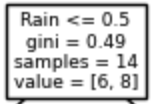

In [ ]:

from sklearn import linear_model

df = pd.read_csv("data.csv")

X = df[['Weight', 'Volume']]
y = df['CO2']

regr = linear_model.LinearRegression()
regr.fit(X, y)

#predict the CO2 emission of a car where the weight is 4000kg, and the volume is 2000cm3:
predictedCO2 = regr.predict([[4000, 2000]])


print('Predicted CO2:', predictedCO2) #CO2 in grams per kilometer
print()
print('Coefficients:', regr.coef_)

#To check accuracy of coefficient, we'll substitute for volume of engine.
#We'll add 100 cm^3 to the engine.

print('Prediction for adding 100 cm^3 to engine:', (100*.00780526) + 125.50902343 )
predictedCO2 = regr.predict([[4000, 2100]])
print('Actual Result:', predictedCO2)
print('Good coefficient!')

print()


FileNotFoundError: [Errno 2] No such file or directory: 'data.csv'

     Outlook Temperature Humidity Rain Go_Outside
0      Sunny         Hot     High   No         No
1      Sunny         Hot     High  Yes         No
2   Overcast         Hot     High   No        Yes
3       Rain         Hot     High  Yes         No
4       Rain        Mild     High   No        Yes
5       Rain        Mild      Low   No        Yes
6   Overcast        Mild      Low   No        Yes
7      Sunny        Mild     High   No         No
8      Sunny        Cool     High   No        Yes
9       Rain        Cool     High   No        Yes
10      Rain        Cool      Low  Yes         No
11  Overcast        Cool      Low   No        Yes
12  Overcast        Cool     High  Yes        Yes
13     Sunny        Mild      Low  Yes         No


    Outlook  Temperature  Humidity  Rain  Go_Outside
0         0            0         0     0           0
1         0            0         0     1           0
2         1            0         0     0           1
3         2            0         0  

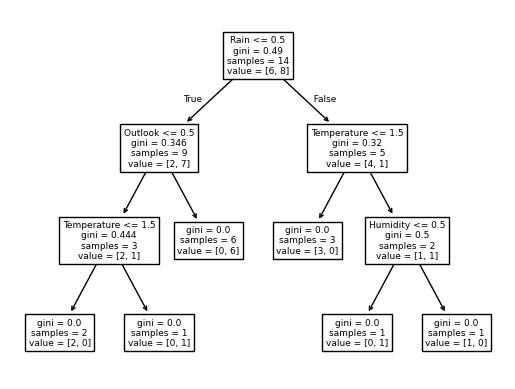

In [ ]:
df = pd.read_csv('weather.csv')

print(df)
print()
print()
print()

Outlook = {'Sunny': 0, 'Overcast': 1, 'Rain': 2}
Temperature = {'Hot': 0, 'Mild': 1, 'Cool': 2}
Humidity = {'High': 0, 'Low': 1}
Rain = {'No': 0, 'Yes': 1}
Go_Outside =  {'No': 0, 'Yes': 1}

df['Outlook'] = df['Outlook'].map(Outlook)
df['Temperature'] = df['Temperature'].map(Temperature)
df['Humidity'] = df['Humidity'].map(Humidity)
df['Rain'] = df['Rain'].map(Rain)
df['Go_Outside'] = df['Go_Outside'].map(Go_Outside)

features = ['Outlook', 'Temperature', 'Humidity', 'Rain']
X = df[features]
y = df['Go_Outside']

dtree = sklearn.tree.DecisionTreeClassifier()
dtree = dtree.fit(X, y)

sklearn.tree.plot_tree(dtree, feature_names=features)

print(df)

# Categorical Data
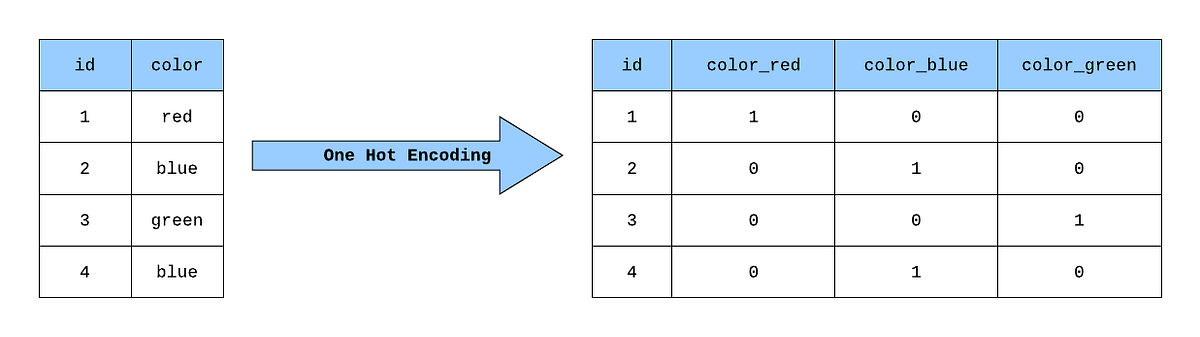

The image above is an example of One Hot Encoding:
- Converts categorial to numeric representation
- If a value in the table is present, it sets the value to 1
- The rest of the values in the row are set to 0

In [ ]:
# read house data
houses = pd.read_csv("houseData.csv")
ohe_neighborhoods = pd.get_dummies(houses[['Neighborhood']]) # one hot encode the neighborhood data
print("Our data set:\n")
print(houses)

X = pd.concat([houses[['Bedrooms', 'Area (sq ft)']], ohe_neighborhoods], axis=1) # updated features
y = houses['Price'] # target  value

regr = sklearn.linear_model.LinearRegression() # build linear regression model
regr.fit(X,y)

# Ask for input
print('\n\n\n')

print('This program is made to predict house prices based on the data set above.\nYou are now able to input the data of the house you would like.')
print('\n\n\n')

Bedrooms = int(input('How many bedrooms does the house have?: '))
Area = int(input('How big is the house in square feet?: '))
Neighborhood = input('What neighborhood?:\n1. Downtown \n2. Rural \n3. Suburb\n')

Neighborhood_Downtown = 0
Neighborhood_Rural = 0
Neighborhood_Suburb = 0

# Set the one-hot encoding based on user input
if Neighborhood == '1':
    Neighborhood_Downtown = 1
elif Neighborhood == '2':
    Neighborhood_Rural = 1
else:
    Neighborhood_Suburb = 1

# Prediction
house = pd.DataFrame({
    'Bedrooms': [Bedrooms],
    'Area (sq ft)': [Area],
    'Neighborhood_Downtown': [Neighborhood_Downtown],
    'Neighborhood_Rural': [Neighborhood_Rural],
    'Neighborhood_Suburb': [Neighborhood_Suburb],
})


# Make sure the columns are in the same order as in X (including all one-hot encoded columns)
house = house[X.columns]

predictedPrice = regr.predict(house)

print('\n\n\n')
print("Predicted Price: $" + str(round(predictedPrice[0], 2))) #Rounded price based off of linear regression model

Our data set:

    Bedrooms  Area (sq ft) Neighborhood   Price
0          3          1500     Downtown  750000
1          4          1800       Suburb  450000
2          2          1000     Downtown  600000
3          3          1200       Suburb  400000
4          5          2200        Rural  250000
5          4          2000     Downtown  850000
6          2           950       Suburb  250000
7          3          1300        Rural  200000
8          4          1600     Downtown  700000
9          5          2400       Suburb  475000
10         3          1100     Downtown  650000
11         2          1400       Suburb  325000
12         3          1450        Rural  230000
13         4          1550     Downtown  720000
14         2          1050       Suburb  280000
15         3          1650        Rural  240000
16         5          2100       Suburb  500000
17         4          1750     Downtown  775000
18         3          1250       Suburb  340000
19         2          120

KeyboardInterrupt: Interrupted by user

# K-means
- Unsupervised learning
- Groups data into K-clusters
- Minimizes variances

##Elbow Method
- When the graph becomes more linear, that's how many clusters should be added

##Inertia
- How well data was clustered
- Measures how compact data points are
- Finds center (centroid) of each cluster

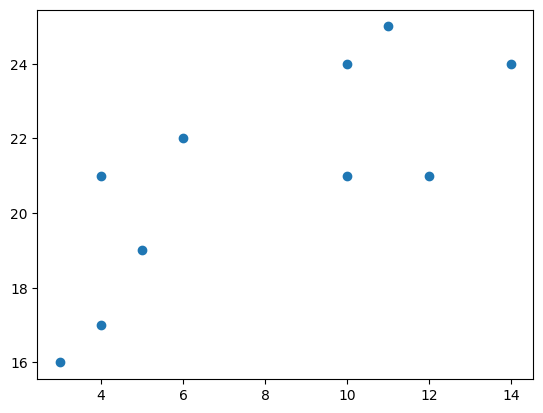

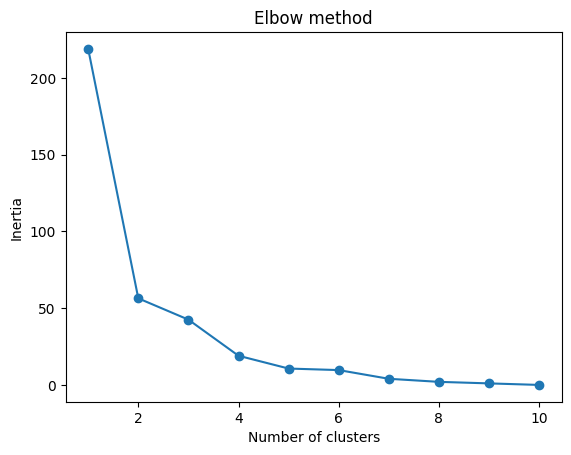

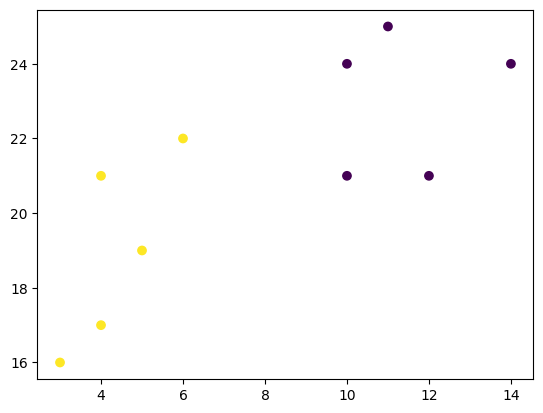

In [ ]:
x = [4, 5, 10, 4, 3, 11, 14 , 6, 10, 12]
y = [21, 19, 24, 17, 16, 25, 24, 22, 21, 21]

plt.scatter(x, y)
plt.show()

from sklearn.cluster import KMeans

data = list(zip(x, y))
inertias = []

for i in range(1,11):
    kmeans = KMeans(n_clusters=i)
    kmeans.fit(data)
    inertias.append(kmeans.inertia_)

plt.plot(range(1,11), inertias, marker='o')
plt.title('Elbow method')
plt.xlabel('Number of clusters')
plt.ylabel('Inertia')
plt.show()

kmeans = KMeans(n_clusters=2)
kmeans.fit(data)

plt.scatter(x, y, c=kmeans.labels_)
plt.show()

#Bootstrap Aggregation
- Prevents overfitting on Decision Trees
- Breaks original set into subsets
- Tries to fit subsets into classification (qualitative) or regresssion (queantitative)

##Aggregation
- Clumps data together into groups
- Reduces amount of data that has to be processed
- Reduces variance and noise in a set


In [ ]:
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.tree import DecisionTreeClassifier

data = datasets.load_wine(as_frame = True)

X = data.data
y = data.target